## Sequence-to-Sequence

+ **序列到序列**问题比我们上一章处理的问题更为复杂。此时存在两个序列：源序列与目标序列。利用前者来预测后者，并且二者的长度甚至可能不相同。
+ 序列到序列问题的一个典型例子就是机器翻译：输入一个句子，输出另一个句子序列。该问题可采用编码器-解码器架构来解决。
+ 语言翻译显然是一项难度很高的任务，因此我们选用一个简单得多的例子来说明编码器-解码器架构的工作原理。

In [3]:
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from train import train


## Data Generation

+ 我们将像之前一样继续绘制相同的正方形，但这次会画出前两个顶点（源序列），并让模型预测接下来的两个顶点（目标序列）。和所有序列相关的问题一样，顺序十分重要，因此仅仅正确得到顶点坐标是不够的；这些顶点需要遵循相同的走向（顺时针或逆时针）。

![](../pictures/seqtoseq1.png)

## Loss
+ 由于我们模型的期望输出是一组坐标序列$(x0, x1)$，因此当前处理的是一个回归问题。所以我们将采用经典的均方误差损失函数，对比目标序列中两个点的预测坐标与真实坐标。

In [4]:
def generate_sequences(n=128, variable_len=False, seed=13):
    """随机生成 n 组沿着正方形轮廓游走的坐标序列，每条序列随机选择起点、
    正向 / 反向绕行；可选固定长度或随机长度，叠加微小噪声；
    标签就是绕行方向，用来做序列分类训练。"""

    basic_corners = np.array([[-1, -1], [-1, 1], [1, 1], [1, -1]])
    # 创建独立随机数生成器
    rng = np.random.default_rng(seed)
    bases = rng.integers(4, size=n)
    if variable_len:
        # 3个可选值：0,1,2 → +2 → 2,3,4
        lengths = rng.integers(3, size=n) + 2
    else:
        lengths = [4] * n

    directions = rng.integers(2, size=n)

    points = [
        basic_corners[[(b + i) % 4 for i in range(4)]][slice(None, None, d * 2 - 1)][:l]
        + rng.standard_normal((l, 2)) * 0.1
        for b, d, l in zip(bases, directions, lengths)
    ]
    return np.array(points), np.array(directions)


## data

各个角点展示了它们的绘制顺序。在第三个正方形中，绘制从右上角（对应蓝色C角点）开始，并沿顺时针方向进行（对应CDAB序列）。该正方形的源序列将依次包含角点C和D（1号与2号），而目标序列将依次包含角点A和B（3号与4号）。

![](../pictures/seqtoseq2.png)

## Encoder-Decoder Architecture
编码器-解码器是由两个模型组合而成：编码器和解码器。

## Encoder

+ 序列编码器的目标：也就是对源数据进行编码，生成表征。
+ 这就是RNN的作用：它们生成一个最终隐藏状态，该状态是输入序列的一种表征。

In [5]:
class Encoder(nn.Module):
    def __init__(self, n_features, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.n_features = n_features
        self.hidden = None
        self.basic_rnn = nn.GRU(self.n_features, self.hidden_dim, batch_first=True)

    def forward(self, X):
        rnn_out, self.hidden = self.basic_rnn(X)
        return rnn_out  # N, L, F

In [6]:
full_seq = torch.tensor([[-1, -1], [-1, 1], [1, 1], [1, -1]]).float().view(1, 4, 2)
source_seq = full_seq[:, :2]  # first two corners
target_seq = full_seq[:, 2:]  # last two corners
torch.manual_seed(21)
encoder = Encoder(n_features=2, hidden_dim=2)
hidden_seq = encoder(source_seq)  # output is N, L, F
hidden_final = hidden_seq[:, -1:]  # takes last hidden state
hidden_final

tensor([[[ 0.3105, -0.5263]]], grad_fn=<SliceBackward0>)

In [ ]:
hidden_seq.shape, hidden_final.shape


## Decoder
+ 解码器的目标是从初始表示生成目标序列并对其进行解码。
+ 听起来是不是非常契合？对源序列进行编码，获取它的表征（最终隐藏状态），再将其输入解码器，从而生成目标序列。

**解码器如何将隐藏状态转换为序列？**
![](../pictures/seqtoseq3.png)

- 第一步中，初始隐藏状态为编码器的最终隐藏状态（$h_f$，蓝色部分）。
- 第一个单元会输出新的隐藏状态（$h_2$）：正如我们在第8章中所见，它既是该单元的输出，也是下一个单元的输入之一。
- 此前，我们仅将最终隐藏状态送入线性层以生成对数概率；而现在，我们会把每个单元的输出送入线性层（$w^Th$），将每个隐藏状态转换为预测坐标（$x_2$）。
- 随后，预测坐标将作为第二步的输入之一（$x_2$）。

在我们这个场景中，解码器的第一个数据点实际上是源序列里的最后一个数据点。这是因为目标序列并不是全新序列，而是源序列的延续。

但情况并非总是如此。在部分自然语言处理任务（例如机器翻译）中，目标序列属于新序列，此时第一个数据点会是某个“特殊”标记，用来标识该新序列的起始位置。

## Decoder
编码器和解码器之间还存在另一个微小但本质的差异：由于解码器会将上一步的预测结果作为下一步的输入，我们必须手动循环生成目标序列。
这也意味着我们需要持续记录每一步的隐藏状态，将上一步的隐藏状态作为下一步的输入。
不过，我们不必把隐藏状态同时设置为前向传播方法 forward() 的输入和输出；可以采用一种简洁（甚至可以说十分巧妙）的方式处理，即将隐藏状态设为解码器模型的属性。

In [7]:
class Decoder(nn.Module):
    def __init__(self, n_features, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.n_features = n_features
        self.hidden = None
        self.basic_rnn = nn.GRU(self.n_features, self.hidden_dim, batch_first=True)
        self.regression = nn.Linear(self.hidden_dim, self.n_features)

    def init_hidden(self, hidden_seq):
        # We only need the final hidden state
        hidden_final = hidden_seq[:, -1:]  # N, 1, H
        # But we need to make it sequence-first
        self.hidden = hidden_final.permute(1, 0, 2)  # 1, N, H

    def forward(self, X):
        # X is N, 1, F
        batch_first_output, self.hidden = self.basic_rnn(X, self.hidden)

        last_output = batch_first_output[:, -1:]
        out = self.regression(last_output)

        # N, 1, F
        return out.view(-1, 1, self.n_features)


- 由于初始隐藏状态必须来自编码器，因此我们需要一种方法来初始化隐藏状态并设置对应的属性。不过编码器的输出是**批次优先（batch-first）**格式，而隐藏状态必须始终为**序列优先（sequence-first）**格式，所以我们要置换它的前两个维度。
- 隐藏状态属性既是循环层的输入，也是循环层的输出。
- 输出的形状必须与输入的形状保持一致，即长度为1的序列。
- 在循环生成目标序列的过程中，`forward()`方法会被多次调用。

In [8]:
decoder = Decoder(n_features=2, hidden_dim=2)
# Initial hidden state will be encoder's final hidden state
decoder.init_hidden(hidden_seq)
# Initial data point is the last element of source sequence
inputs = source_seq[:, -1:]
target_len = 2
for i in range(target_len):
    print(f"Hidden: {decoder.hidden}")
    out = decoder(inputs)  # Predicts coordinates
    print(f"Output: {out}\n")
    # Predicted coordinates are next step's inputs
    inputs = out

Hidden: tensor([[[ 0.3105, -0.5263]]], grad_fn=<PermuteBackward0>)
Output: tensor([[[ 0.0338, -0.5005]]], grad_fn=<ViewBackward0>)

Hidden: tensor([[[0.0930, 0.2894]]], grad_fn=<StackBackward0>)
Output: tensor([[[ 0.0926, -0.5201]]], grad_fn=<ViewBackward0>)



## Problem
不过上述方法存在一个问题：未经训练的模型会产生非常糟糕的预测结果，而这些预测结果仍会被用作后续步骤的输入。这会无端增加模型训练的难度，因为某一步的预测误差既来源于（未训练的）模型本身，也来自上一步产生的预测误差。

## Teaching Force
原理很简单：不使用模型的预测结果，而是改用目标序列中的真实数据。

### 测试阶段，模型只能使用自身在前序步骤中生成的预测结果，没有其他选择。
问题在于，采用教师强制训练的模型，会基于目标序列每一步的正确输入来最小化损失。然而在测试阶段，这种理想情况永远不会出现，因此当模型将自身的预测结果作为输入时，性能往往会变差。

心存疑虑时，不妨抛硬币，字面意义上的抛硬币。在训练过程中，模型有时会采用教师强制策略，有时则会使用自身的预测结果。因此我们会偶尔向模型提供真实输入来辅助它，但同时仍要求模型具备足够的鲁棒性，能够生成并使用自身的输入。

In [9]:
# Initial hidden state will be encoder's final hidden state
decoder.init_hidden(hidden_seq)
# Initial data point is the last element of source sequence
inputs = source_seq[:, -1:]
teacher_forcing_prob = 0.5
target_len = 2
for i in range(target_len):
    print(f"Hidden: {decoder.hidden}")
    out = decoder(inputs)
    print(f"Output: {out}\n")
    # If it is teacher forcing
    if torch.rand(1) <= teacher_forcing_prob:
        # Takes the actual element
        inputs = target_seq[:, i : i + 1]
    else:
        # Otherwise uses the last predicted output
        inputs = out

Hidden: tensor([[[ 0.3105, -0.5263]]], grad_fn=<PermuteBackward0>)
Output: tensor([[[ 0.0338, -0.5005]]], grad_fn=<ViewBackward0>)

Hidden: tensor([[[0.0930, 0.2894]]], grad_fn=<StackBackward0>)
Output: tensor([[[ 0.2530, -0.6326]]], grad_fn=<ViewBackward0>)



## Encoder + Decoder
我们可以把目前已经实现的各个零散模块整合为一个模型：给定编码器与解码器模型，该模型实现`forward()`方法，将输入拆分为源序列与目标序列，循环执行目标序列的生成过程，并在训练模式下启用教师强制（teacher forcing）。

In [10]:
class EncoderDecoder(nn.Module):
    def __init__(
        self, encoder, decoder, input_len, target_len, teacher_forcing_prob=0.5
    ) -> None:
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.input_len = input_len
        self.target_len = target_len
        self.teacher_forcing_prob = teacher_forcing_prob
        self.outputs: torch.Tensor  # Note: no initial value

    def init_outputs(self, batch_size):
        device = next(self.parameters()).device
        self.outputs = torch.zeros(
            batch_size, self.target_len, self.encoder.n_features
        ).to(device)

    def store_output(self, i, out):
        self.outputs[:, i : i + 1, :] = out

    def forward(self, X):
        # splits the data in source and target sequences
        # the target seq will be empty in testing mode
        # N, L, F
        source_seq = X[:, : self.input_len, :]
        target_seq = X[:, self.input_len :, :]
        self.init_outputs(X.shape[0])

        # Encoder expected N, L, F
        hidden_seq = self.encoder(source_seq)
        # Output is N, L, H
        self.decoder.init_hidden(hidden_seq)

        # The last input of the encoder is also
        # the first input of the decoder

        dec_inputs = source_seq[:, -1:, :]

        # Generates as many outputs as the target length
        for i in range(self.target_len):
            # Output of decoder is N, 1, F
            out = self.decoder(dec_inputs)
            self.store_output(i, out)

            prob = self.teacher_forcing_prob
            # In evaluation / test the target sequence is
            # unknown, so we cannot use teacher forcing

            if not self.training:
                prob = 0

            if torch.rand(1) < prob:
                # Takes the actual element
                dec_inputs = target_seq[:, i : i + 1, :]
            else:
                # Otherwise uses the last predicted output
                dec_inputs = out

        return self.outputs


In [11]:
points, directions = generate_sequences(n=256, seed=13)
full_train = torch.as_tensor(points).float()
target_train = full_train[:, 2:]

In [12]:
test_points, test_directions = generate_sequences(seed=19)
full_test = torch.as_tensor(test_points).float()
source_test = full_test[:, :2]
target_test = full_test[:, 2:]

In [13]:
train_data = TensorDataset(full_train, target_train)
test_data = TensorDataset(source_test, target_test)
train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
test_loader = DataLoader(test_data, batch_size=16)

In [14]:
encoder = Encoder(n_features=2, hidden_dim=2)
decoder = Decoder(n_features=2, hidden_dim=2)
model = EncoderDecoder(
    encoder, decoder, input_len=2, target_len=2, teacher_forcing_prob=0.5
)
loss = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [15]:
train_losses, test_losses = train(
    model, train_loader, test_loader, loss, optimizer, 100
)

Epoch 1/100 - loss: 1.0278 - val_loss: 0.9293
Epoch 2/100 - loss: 0.8784 - val_loss: 0.8246
Epoch 3/100 - loss: 0.7911 - val_loss: 0.7731
Epoch 4/100 - loss: 0.7588 - val_loss: 0.7706
Epoch 5/100 - loss: 0.7499 - val_loss: 0.7619
Epoch 6/100 - loss: 0.7388 - val_loss: 0.7542
Epoch 7/100 - loss: 0.7168 - val_loss: 0.7304
Epoch 8/100 - loss: 0.6833 - val_loss: 0.6918
Epoch 9/100 - loss: 0.6452 - val_loss: 0.6648
Epoch 10/100 - loss: 0.6159 - val_loss: 0.6369
Epoch 11/100 - loss: 0.5891 - val_loss: 0.6115
Epoch 12/100 - loss: 0.5591 - val_loss: 0.5779
Epoch 13/100 - loss: 0.5228 - val_loss: 0.5388
Epoch 14/100 - loss: 0.4857 - val_loss: 0.5014
Epoch 15/100 - loss: 0.4471 - val_loss: 0.4552
Epoch 16/100 - loss: 0.4187 - val_loss: 0.4227
Epoch 17/100 - loss: 0.4008 - val_loss: 0.4101
Epoch 18/100 - loss: 0.3887 - val_loss: 0.4121
Epoch 19/100 - loss: 0.3794 - val_loss: 0.4144
Epoch 20/100 - loss: 0.3720 - val_loss: 0.4175
Epoch 21/100 - loss: 0.3748 - val_loss: 0.4096
Epoch 22/100 - loss: 0

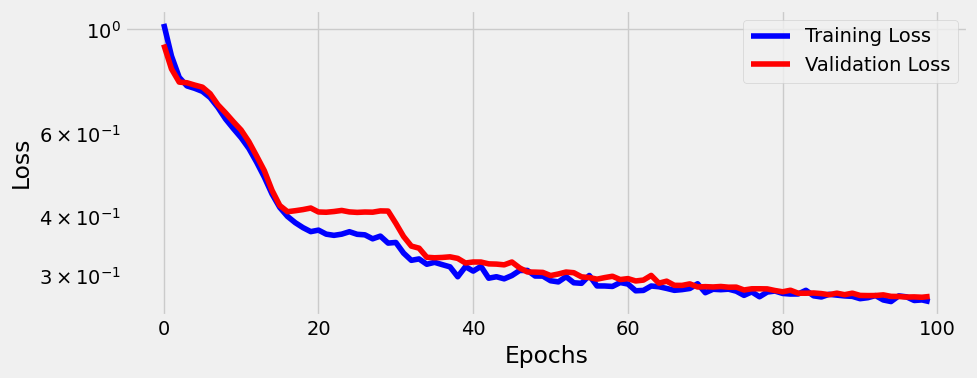

In [16]:
import matplotlib.pyplot as plt

plt.style.use("fivethirtyeight")


def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label="Training Loss", c="b")
    plt.plot(test_losses, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()


In [19]:
def sequence_pred(model, X, directions=None, n_rows=2, n_cols=5):
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axs = axs.flatten()

    for e, ax in enumerate(axs):
        first_corners = X[e, :2, :]
        model.eval()
        next_corners = (
            model(X[e : e + 1, :2].to(X.device)).squeeze().detach().cpu().numpy()
        )
        pred_corners = np.concatenate([first_corners, next_corners], axis=0)

        for j, corners in enumerate([X[e], pred_corners]):
            for i in range(4):
                coords = corners[i]
                color = "k"
                ax.scatter(*coords, c=color, s=400)
                if i == 3:
                    start = -1
                else:
                    start = i
                if (not j) or (j and i):
                    ax.plot(
                        *corners[[start, start + 1]].T,
                        c="k",
                        lw=2,
                        alpha=0.5,
                        linestyle="--" if j else "-",
                    )
                ax.text(
                    *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12
                )
                if directions is not None:
                    ax.set_title(f"{'Counter-' if not directions[e] else ''}Clockwise")

        ax.set_xlabel(r"$x_0$")
        ax.set_ylabel(r"$x_1$", rotation=0)
        ax.set_xlim([-1.45, 1.45])
        ax.set_ylim([-1.45, 1.45])

    fig.tight_layout()
    return fig


C:\Users\cuish\AppData\Local\Temp\ipykernel_18312\1587516764.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12


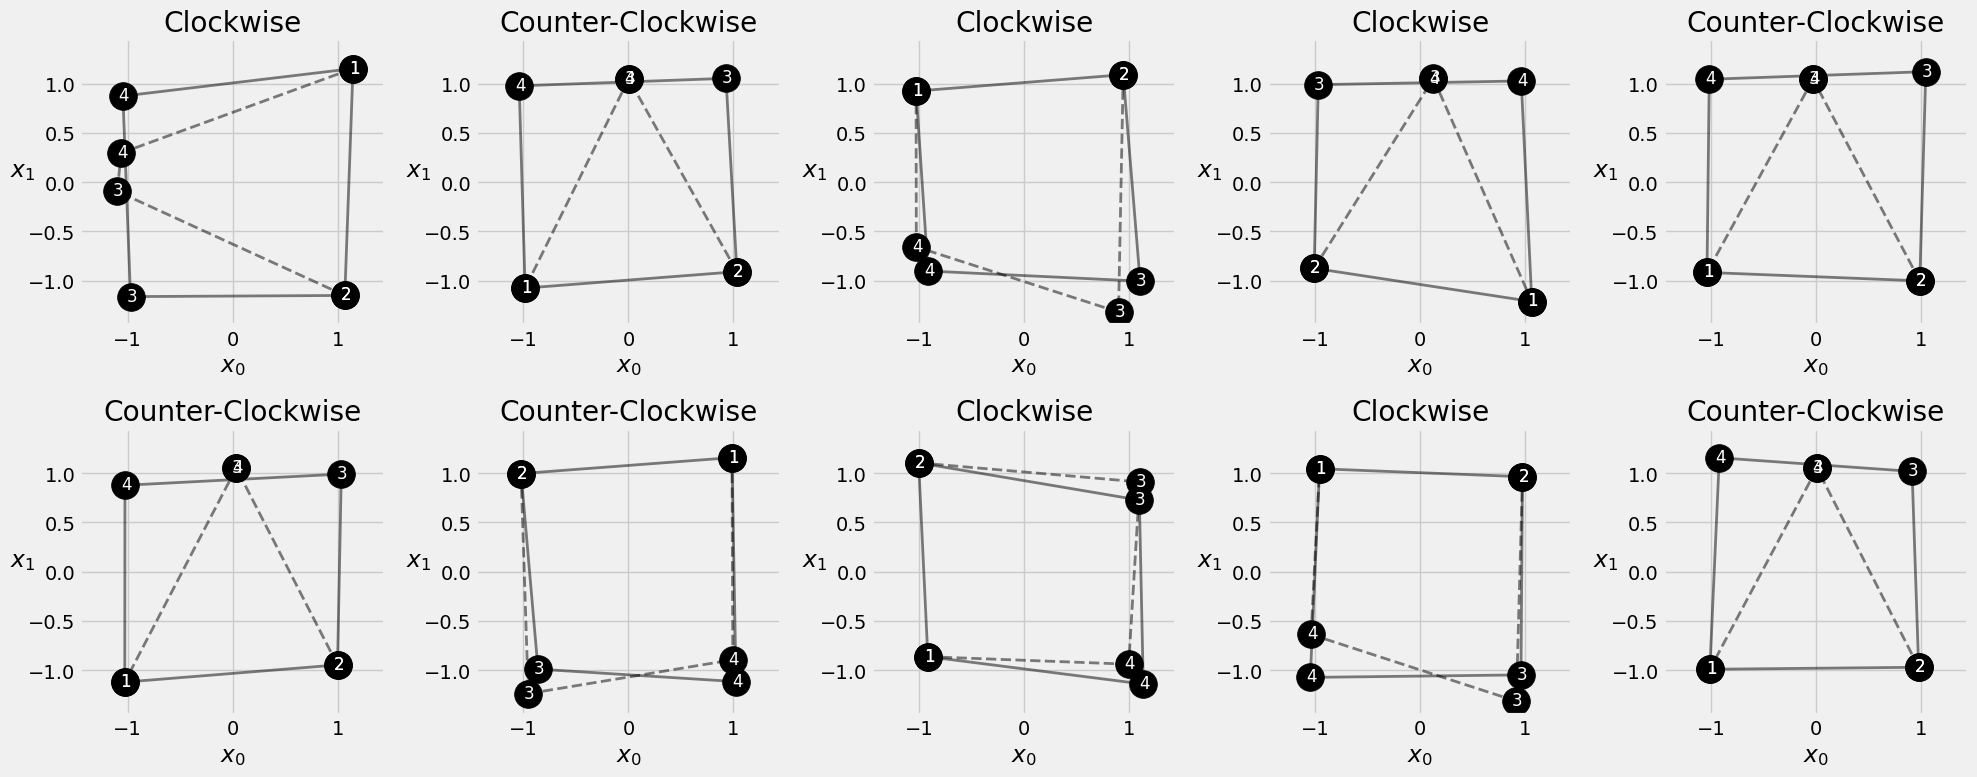

In [20]:
fig = sequence_pred(model, full_test, directions=test_directions)